# Instance-Based vs Model-Based Learning
## Memorization vs. Generalization in Machine Learning

This notebook demonstrates the difference with a small student Pass/Fail dataset.

- **Instance-based:** predictions depend on nearby stored examples.
- **Model-based:** a fitted model learns a decision boundary from training data.

We will use K-Nearest Neighbors (KNN) and Logistic Regression as examples. The results are illustrations of the methods, not proof that one approach is always better.


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


## 2. Create the student dataset

In [2]:
# Features: play hours and study hours
X = np.array([
    [8, 1],
    [7, 2],
    [6, 2],
    [2, 8],
    [3, 7],
    [1, 9],
])

# 0 = Fail, 1 = Pass
y = np.array([0, 0, 0, 1, 1, 1])

df = pd.DataFrame(X, columns=["Play Hours", "Study Hours"])
df["Result"] = np.where(y == 1, "Pass", "Fail")
df


,Play Hours,Study Hours,Result
0,8,1,Fail
1,7,2,Fail
2,6,2,Fail
3,2,8,Pass
4,3,7,Pass
5,1,9,Pass


## 3. Plot the training examples

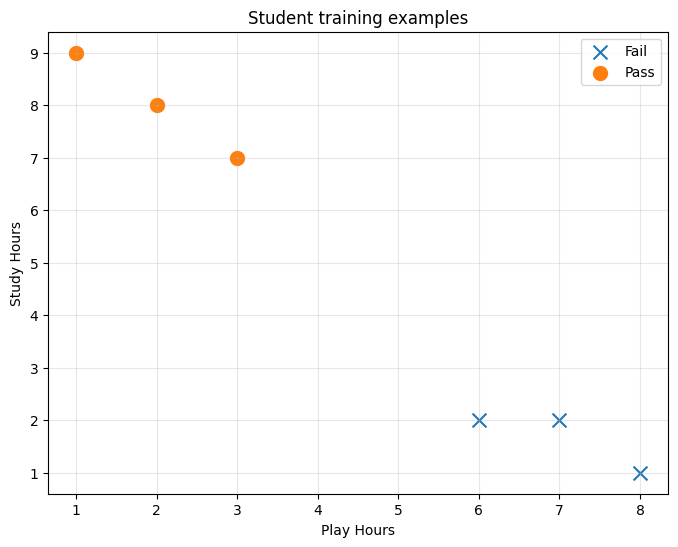

In [3]:
plt.figure(figsize=(8, 6))
for label, name, marker in [(0, "Fail", "x"), (1, "Pass", "o")]:
    mask = y == label
    plt.scatter(X[mask, 0], X[mask, 1], label=name, marker=marker, s=100)

plt.xlabel("Play Hours")
plt.ylabel("Study Hours")
plt.title("Student training examples")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## 4. Instance-based learning with KNN

KNN stores the training examples and uses distances to find nearby examples when a new point arrives.

For a fairer distance comparison between play and study hours, we standardize features in a pipeline. The pipeline is fitted on the training data only.


In [4]:
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)
knn.fit(X, y)

new_student = np.array([[6, 3]])
prediction = knn.predict(new_student)[0]
probabilities = knn.predict_proba(new_student)[0]

print("New student [play hours, study hours]:", new_student[0])
print("KNN prediction:", "Pass" if prediction == 1 else "Fail")
print("Class probabilities:", {
    "Fail": round(probabilities[0], 3),
    "Pass": round(probabilities[1], 3)
})


New student [play hours, study hours]: [6 3]
KNN prediction: Fail
Class probabilities: {'Fail': np.float64(1.0), 'Pass': np.float64(0.0)}


### Visualize the KNN decision regions

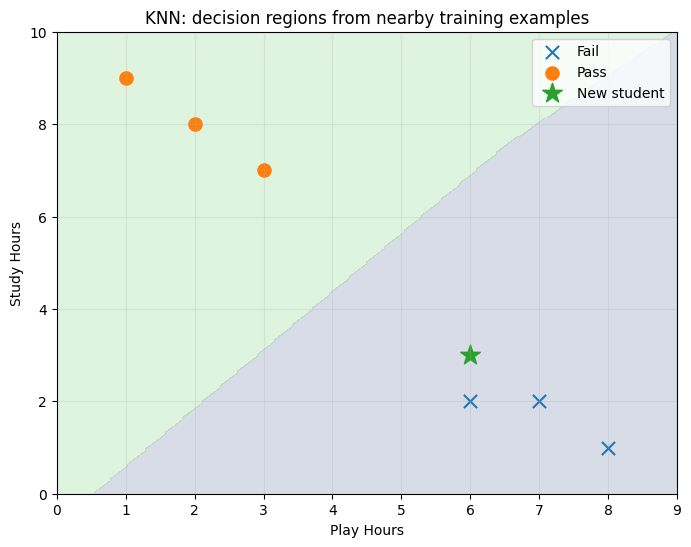

In [5]:
x_min, x_max = 0, 9
y_min, y_max = 0, 10
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
grid = np.c_[xx.ravel(), yy.ravel()]
Z_knn = knn.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z_knn, alpha=0.2, levels=[-0.5, 0.5, 1.5])
for label, name, marker in [(0, "Fail", "x"), (1, "Pass", "o")]:
    mask = y == label
    plt.scatter(X[mask, 0], X[mask, 1], label=name, marker=marker, s=90)
plt.scatter(new_student[0, 0], new_student[0, 1],
            marker="*", s=220, label="New student")
plt.xlabel("Play Hours")
plt.ylabel("Study Hours")
plt.title("KNN: decision regions from nearby training examples")
plt.grid(True, alpha=0.25)
plt.legend()
plt.show()


## 5. Model-based learning with Logistic Regression

In [6]:
log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)
log_reg.fit(X, y)

prediction_lr = log_reg.predict(new_student)[0]
probabilities_lr = log_reg.predict_proba(new_student)[0]

print("New student [play hours, study hours]:", new_student[0])
print("Logistic Regression prediction:", "Pass" if prediction_lr == 1 else "Fail")
print("Class probabilities:", {
    "Fail": round(probabilities_lr[0], 3),
    "Pass": round(probabilities_lr[1], 3)
})


New student [play hours, study hours]: [6 3]
Logistic Regression prediction: Fail
Class probabilities: {'Fail': np.float64(0.726), 'Pass': np.float64(0.274)}


### Visualize the Logistic Regression decision regions

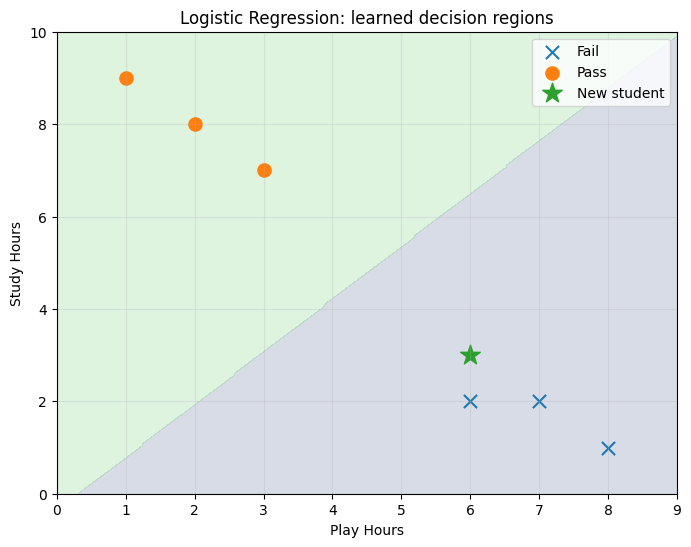

In [7]:
Z_lr = log_reg.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z_lr, alpha=0.2, levels=[-0.5, 0.5, 1.5])
for label, name, marker in [(0, "Fail", "x"), (1, "Pass", "o")]:
    mask = y == label
    plt.scatter(X[mask, 0], X[mask, 1], label=name, marker=marker, s=90)
plt.scatter(new_student[0, 0], new_student[0, 1],
            marker="*", s=220, label="New student")
plt.xlabel("Play Hours")
plt.ylabel("Study Hours")
plt.title("Logistic Regression: learned decision regions")
plt.grid(True, alpha=0.25)
plt.legend()
plt.show()


## 6. Compare the two approaches

The models may make the same prediction on this tiny dataset, but their learning approaches differ. KNN bases a prediction on nearby stored examples. Logistic Regression learns coefficients that define a decision function.

This small dataset is intentionally simple. It is for intuition, not for evaluating real student outcomes or comparing model quality.

In [8]:
comparison = pd.DataFrame({
    "Approach": ["Instance-based: KNN", "Model-based: Logistic Regression"],
    "Prediction for [6, 3]": [
        "Pass" if prediction == 1 else "Fail",
        "Pass" if prediction_lr == 1 else "Fail"
    ],
    "How it predicts": [
        "Uses nearest stored examples",
        "Uses learned model parameters"
    ]
})
comparison


,Approach,"Prediction for [6, 3]",How it predicts
0,Instance-based: KNN,Fail,Uses nearest stored examples
1,Model-based: Logistic Regression,Fail,Uses learned model parameters


## 7. What happens when K changes?

In KNN, changing \(K\) changes how many neighbors vote. A small value can be sensitive to individual examples; a larger value creates a broader neighborhood. Feature scaling and the distance metric also matter.

In [9]:
k_values = [1, 3, 5]
k_results = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    model.fit(X, y)
    pred = model.predict(new_student)[0]
    k_results.append({
        "K": k,
        "Prediction": "Pass" if pred == 1 else "Fail"
    })

pd.DataFrame(k_results)


,K,Prediction
0,1,Fail
1,3,Fail
2,5,Fail


## 8. Self-check

1. Which approach relies on similarity to stored examples?
2. Which approach learns coefficients during training in this demonstration?
3. Why do we standardize the features for KNN?
4. Does instance-based learning mean the algorithm cannot generalize?
5. Why might KNN prediction be slower on a very large dataset?

### Answers

1. Instance-based learning (KNN here).
2. Logistic Regression.
3. Distance-based methods can be affected by features measured on different scales.
4. No. KNN can generalize to unseen examples using similarity to stored instances.
5. It may need to calculate distances to many stored training examples.
